In [1]:
import requests
import pandas as pd

URL_MENSUAL = "https://data.cityofnewyork.us/resource/fvp3-gcb2.json"

r = requests.get(URL_MENSUAL, params={"$limit": 5})
r.raise_for_status()
muestra = pd.DataFrame(r.json())

print(f"Columnas: {len(muestra.columns)}\n")
for c in muestra.columns:
    print(f"  {c}")

Columnas: 8

  calendar_year
  month
  property_id
  property_name
  parent_property_id
  parent_property_name
  natural_gas_use_kbtu
  electricity_use_kbtu


In [2]:
muestra.head()


,calendar_year,month,property_id,property_name,parent_property_id,parent_property_name,natural_gas_use_kbtu,electricity_use_kbtu
0,2020,20-Feb,2630964,655 Tysens Lane,6803136,Tysens Park Apartments,1131542.9,188325.4
1,2020,20-Mar,2630964,655 Tysens Lane,6803136,Tysens Park Apartments,1035367.1,206160.4
2,2020,20-Apr,2630964,655 Tysens Lane,6803136,Tysens Park Apartments,814973.1,207192.3
3,2020,20-May,2630964,655 Tysens Lane,6803136,Tysens Park Apartments,556320.1,239886.2
4,2020,20-Jun,2630964,655 Tysens Lane,6803136,Tysens Park Apartments,340029,339337.1


In [3]:
muestra.dtypes

calendar_year           str
month                   str
property_id             str
property_name           str
parent_property_id      str
parent_property_name    str
natural_gas_use_kbtu    str
electricity_use_kbtu    str
dtype: object

In [4]:
cols_numericas = ["calendar_year", "natural_gas_use_kbtu", "electricity_use_kbtu"]

for col in cols_numericas:
    muestra[col] = pd.to_numeric(muestra[col], errors="coerce")

muestra.dtypes

calendar_year             int64
month                       str
property_id                 str
property_name               str
parent_property_id          str
parent_property_name        str
natural_gas_use_kbtu    float64
electricity_use_kbtu    float64
dtype: object

In [5]:
muestra["electricity_kwh"] = muestra["electricity_use_kbtu"] / 3.412

muestra[["electricity_use_kbtu", "electricity_kwh"]]

,electricity_use_kbtu,electricity_kwh
0,188325.4,55195.017585
1,206160.4,60422.157093
2,207192.3,60724.589683
3,239886.2,70306.623681
4,339337.1,99454.015240


In [6]:
muestra["month"].unique()


<StringArray>
['20-Feb', '20-Mar', '20-Apr', '20-May', '20-Jun']
Length: 5, dtype: str

In [7]:
MESES = {"Jan": 1, "Feb": 2, "Mar": 3, "Apr": 4, "May": 5, "Jun": 6,
         "Jul": 7, "Aug": 8, "Sep": 9, "Oct": 10, "Nov": 11, "Dec": 12}

muestra["mes"] = muestra["month"].str.split("-").str[1].map(MESES)

In [8]:
muestra[["calendar_year", "month", "mes"]]

,calendar_year,month,mes
0,2020,20-Feb,2
1,2020,20-Mar,3
2,2020,20-Apr,4
3,2020,20-May,5
4,2020,20-Jun,6


In [9]:
muestra["mes"].isna().sum()

np.int64(0)

In [10]:
URL_ANUAL = "https://data.cityofnewyork.us/resource/5zyy-y8am.json"

r = requests.get(URL_ANUAL, params={"$limit": 5})
r.raise_for_status()
anual = pd.DataFrame(r.json())

print(f"Columnas: {len(anual.columns)}\n")
for c in anual.columns:
    print(f"  {c}")

Columnas: 254

  report_year
  property_id
  property_name
  parent_property_id
  parent_property_name
  year_ending
  nyc_borough_block_and_lot
  nyc_building_identification
  address_1
  city
  postal_code
  primary_property_type_self
  primary_property_type
  national_median_reference
  list_of_all_property_use
  largest_property_use_type
  largest_property_use_type_1
  _2nd_largest_property_use
  _2nd_largest_property_use_1
  _3rd_largest_property_use
  _3rd_largest_property_use_1
  year_built
  construction_status
  number_of_buildings
  occupancy
  metered_areas_energy
  metered_areas_water
  energy_star_score
  national_median_energy_star
  target_energy_star_score
  reason_s_for_no_score
  energy_star_certification
  energy_star_certification_1
  site_eui_kbtu_ft
  weather_normalized_site_eui
  national_median_site_eui
  site_energy_use_kbtu
  weather_normalized_site_energy
  electricity_weather_normalized
  electricity_weather_normalized_1
  natural_gas_weather_normalized
  na

In [11]:
anual[["property_id", "report_year", "primary_property_type",
       "office_gross_floor_area_ft"]].head()

,property_id,report_year,primary_property_type,office_gross_floor_area_ft
0,6414946,2022,Non-Refrigerated Warehouse,Not Available
1,9793770,2022,Multifamily Housing,Not Available
2,10177418,2022,Mixed Use Property,17598
3,13511507,2022,Multifamily Housing,Not Available
4,14009907,2022,Medical Office,3760


In [12]:
r = requests.get(URL_ANUAL, params={
    "$limit": 50000,
    "$select": "property_id,report_year,primary_property_type,office_gross_floor_area_ft,year_built,occupancy",
    "primary_property_type": "Office"
})
r.raise_for_status()
oficinas = pd.DataFrame(r.json())

print(f"Filas: {len(oficinas)}")
print(oficinas["report_year"].value_counts().sort_index())

Filas: 7578
report_year
2022    2410
2023    2571
2024    2597
Name: count, dtype: int64


In [13]:
of23 = oficinas[oficinas["report_year"] == "2023"].copy()

of23["pies2"] = pd.to_numeric(of23["office_gross_floor_area_ft"], errors="coerce")

print(f"Oficinas 2023: {len(of23)}")
print(f"Sin superficie válida: {of23['pies2'].isna().sum()}")
print()
print(of23["pies2"].describe())

Oficinas 2023: 2571
Sin superficie válida: 0

count    2.571000e+03
mean     2.007214e+05
std      3.360130e+05
min      7.400000e+01
25%      4.187900e+04
50%      8.050000e+04
75%      2.138075e+05
max      6.031626e+06
Name: pies2, dtype: float64


In [14]:
antes = len(of23)

of23 = of23[of23["pies2"] >= 25000].copy()

descartados = antes - len(of23)
print(f"Antes del filtro:      {antes:,}")
print(f"Descartados (<25k ft²): {descartados:,}")
print(f"Quedan:                {len(of23):,}")
print()
print(of23["pies2"].describe())

Antes del filtro:      2,571
Descartados (<25k ft²): 168
Quedan:                2,403

count    2.403000e+03
mean     2.136623e+05
std      3.438515e+05
min      2.500000e+04
25%      4.770600e+04
50%      9.155400e+04
75%      2.281835e+05
max      6.031626e+06
Name: pies2, dtype: float64


LINAJE
Oficinas 2023: 2,571
- Superficie < 25,000 ft²: -168
Quedan: 2,403


In [15]:
r = requests.get(URL_MENSUAL, params={
    "$limit": 500000,
    "$where": "calendar_year = 2023"
})
r.raise_for_status()
mensual = pd.DataFrame(r.json())

print(f"Filas: {len(mensual):,}")
print(f"Edificios únicos: {mensual['property_id'].nunique():,}")
print()
print("Formatos de mes encontrados:")
print(mensual["month"].unique())

Filas: 404,208
Edificios únicos: 33,062

Formatos de mes encontrados:
<StringArray>
['23-Apr', '23-May', '23-Jan', '23-Feb', '23-Mar', '23-Jun', '23-Jul',
 '23-Aug', '23-Sep', '23-Oct', '23-Nov', '23-Dec']
Length: 12, dtype: str


Aplicamos transformaciones

In [16]:

COL_ELEC = "electricity_use_grid_kbtu_"

mensual[COL_ELEC] = pd.to_numeric(mensual[COL_ELEC], errors="coerce")

mensual["electricity_kwh"] = mensual[COL_ELEC] / 3.412

mensual["mes"] = mensual["month"].str.split("-").str[1].map(MESES)

print(f"Meses sin convertir: {mensual['mes'].isna().sum()}")
print(f"Consumo eléctrico inválido: {mensual['electricity_kwh'].isna().sum():,}")
print(f"Total de filas: {len(mensual):,}")

Meses sin convertir: 0
Consumo eléctrico inválido: 76,491
Total de filas: 404,208


unimos edificios

In [17]:
ids_oficinas = set(of23["property_id"])

mensual_of = mensual[mensual["property_id"].isin(ids_oficinas)].copy()

print(f"Filas de oficinas:     {len(mensual_of):,}")
print(f"Edificios distintos:   {mensual_of['property_id'].nunique():,}")
print(f"De los {len(of23):,} esperados")
print()
print(f"Consumo inválido aquí: {mensual_of['electricity_kwh'].isna().sum():,} "
      f"({100*mensual_of['electricity_kwh'].isna().mean():.1f}%)")

Filas de oficinas:     28,860
Edificios distintos:   2,345
De los 2,403 esperados

Consumo inválido aquí: 3,781 (13.1%)


In [18]:
validos = mensual_of.dropna(subset=["electricity_kwh"])

meses_por_edificio = validos.groupby("property_id")["mes"].nunique()

print("Meses válidos por edificio:")
print(meses_por_edificio.value_counts().sort_index())
print()
print(f"Con los 12 meses completos: {(meses_por_edificio == 12).sum():,}")
print()

filas = validos.groupby("property_id").size()
print(f"Edificios con filas duplicadas: {(filas > meses_por_edificio).sum():,}")

Meses válidos por edificio:
mes
4        1
11       2
12    2035
Name: count, dtype: int64

Con los 12 meses completos: 2,035

Edificios con filas duplicadas: 53


In [19]:
panel = (validos
         .groupby(["property_id", "mes"], as_index=False)["electricity_kwh"]
         .sum())

print(f"Filas: {len(panel):,}")
print(f"Edificios: {panel['property_id'].nunique():,}")
print(f"Filas por edificio: {len(panel) / panel['property_id'].nunique():.2f}")
print()
print(panel.head(3))

Filas: 24,446
Edificios: 2,038
Filas por edificio: 12.00

  property_id  mes  electricity_kwh
0    10018699    2     13214.126612
1    10018699    3     14714.888628
2    10018699    4     14237.397421


El CLima


In [20]:
URL_CLIMA = "https://archive-api.open-meteo.com/v1/archive"

r = requests.get(URL_CLIMA, params={
    "latitude": 40.7823,
    "longitude": -73.9656,
    "start_date": "2023-01-01",
    "end_date": "2023-12-31",
    "daily": "temperature_2m_mean",
    "timezone": "America/New_York"
})
r.raise_for_status()
datos = r.json()["daily"]

clima = pd.DataFrame({
    "fecha": pd.to_datetime(datos["time"]),
    "temp_c": datos["temperature_2m_mean"]
})

print(f"Días: {len(clima)}")
print(f"Nulos: {clima['temp_c'].isna().sum()}")
print(clima.head(3))

Días: 365
Nulos: 0
       fecha  temp_c
0 2023-01-01     9.0
1 2023-01-02     8.0
2 2023-01-03     9.6


ahora promediamos a mes

In [21]:
clima_mes = (clima
             .assign(mes=clima["fecha"].dt.month)
             .groupby("mes", as_index=False)["temp_c"]
             .mean())

print(clima_mes)

    mes     temp_c
0     1   4.580645
1     2   3.221429
2     3   5.203226
3     4  12.556667
4     5  15.596774
5     6  19.980000
6     7  24.674194
7     8  22.874194
8     9  19.870000
9    10  14.567742
10   11   6.463333
11   12   5.032258


Ahora unimos

In [22]:
panel = panel.merge(clima_mes, on="mes", how="left")

panel = panel.merge(
    of23[["property_id", "pies2", "year_built", "occupancy"]],
    on="property_id", how="left")

print(f"Filas: {len(panel):,}")
print(f"Edificios: {panel['property_id'].nunique():,}")
print(f"Nulos por columna:\n{panel.isna().sum()}")
print()
print(panel.head())

Filas: 25,130
Edificios: 2,038
Nulos por columna:
property_id        0
mes                0
electricity_kwh    0
temp_c             0
pies2              0
year_built         0
occupancy          0
dtype: int64

  property_id  mes  electricity_kwh     temp_c    pies2 year_built occupancy
0    10018699    2     13214.126612   3.221429  47777.0       1988        95
1    10018699    3     14714.888628   5.203226  47777.0       1988        95
2    10018699    4     14237.397421  12.556667  47777.0       1988        95
3    10018699    5     16216.500586  15.596774  47777.0       1988        95
4    10018699    6     16046.981243  19.980000  47777.0       1988        95


In [23]:
panel = (validos
         .groupby(["property_id", "mes"], as_index=False)["electricity_kwh"]
         .sum())

panel = panel.merge(clima_mes, on="mes", how="left")

panel = panel.merge(
    of23[["property_id", "pies2", "year_built", "occupancy"]],
    on="property_id", how="left")

print(f"Filas: {len(panel):,}  (esperado: 24,446)")
print(f"Columnas: {panel.columns.tolist()}")

Filas: 25,130  (esperado: 24,446)
Columnas: ['property_id', 'mes', 'electricity_kwh', 'temp_c', 'pies2', 'year_built', 'occupancy']


In [24]:
print(f"Filas en of23: {len(of23):,}")
print(f"property_id únicos: {of23['property_id'].nunique():,}")
print(f"Duplicados: {of23['property_id'].duplicated().sum():,}")

Filas en of23: 2,403
property_id únicos: 2,345
Duplicados: 58


In [25]:
dups = of23[of23["property_id"].duplicated(keep=False)].sort_values("property_id")
print(dups[["property_id", "pies2", "year_built", "occupancy"]].head(10))

     property_id      pies2 year_built occupancy
2737    10179956    61745.0       1911       100
2743    10179956    61745.0       1911       100
3000     1439342  1859513.0       1915        85
2982     1439342  1859513.0       1915        85
2891    15103400   407767.0       1964       100
2897    15103400   407767.0       1964       100
2917    15139221   154380.0       1928        90
2893    15139221   154380.0       1928        90
3916    15632583   553134.0       1900        85
3913    15632583   553134.0       1900        85


eliminamos duplicados

In [26]:
of23_unico = of23.drop_duplicates(subset="property_id", keep="first").copy()

print(f"Antes: {len(of23):,}  Después: {len(of23_unico):,}")

Antes: 2,403  Después: 2,345


Ahora unimos

In [27]:
panel = (validos
         .groupby(["property_id", "mes"], as_index=False)["electricity_kwh"]
         .sum())

panel = panel.merge(clima_mes, on="mes", how="left")

panel = panel.merge(
    of23_unico[["property_id", "pies2", "year_built", "occupancy"]],
    on="property_id", how="left")

print(f"Filas: {len(panel):,}  (esperado: 24,446)")
print(f"Edificios: {panel['property_id'].nunique():,}")
print(f"Nulos: {panel.isna().sum().sum()}")

Filas: 24,446  (esperado: 24,446)
Edificios: 2,038
Nulos: 0


Oficinas en 2023 (dataset anual):        2,403
- Reportes duplicados:                     -58
- Superficie < 25,000 ft²:                -168   [aplicado antes]
Edificios únicos:                        2,345
- Sin consumo eléctrico reportado:        -307
Edificios con datos válidos:             2,038
  (53 con múltiples medidores, consolidados por suma)
- Sin los 12 meses completos:               -3
= EDIFICIOS MODELABLES:                  2,035

In [28]:
panel.to_csv("datos/panel_oficinas_2023.csv", index=False)
print("Guardado")

Guardado


## Bloque 3 — Modelo de un edificio

Antes de modelar 2,035 edificios, se valida el enfoque en uno solo.

**El modelo (3P-C, ASHRAE Guideline 14):**

    kWh_mes = base + pendiente × max(0, temp_mes − punto_quiebre)

Tres parámetros:

| Parámetro | Significado físico |
|---|---|
| `base` | Consumo independiente del clima: iluminación, elevadores, equipos |
| `punto_quiebre` | Temperatura a la que el edificio empieza a enfriar (punto de balance) |
| `pendiente` | kWh adicionales por cada grado por encima del quiebre |

**Ajuste por búsqueda en malla:** para cada punto de quiebre candidato se
transforma la temperatura, se corre una regresión lineal simple y se guarda
el error. Se conserva el candidato con menor error.

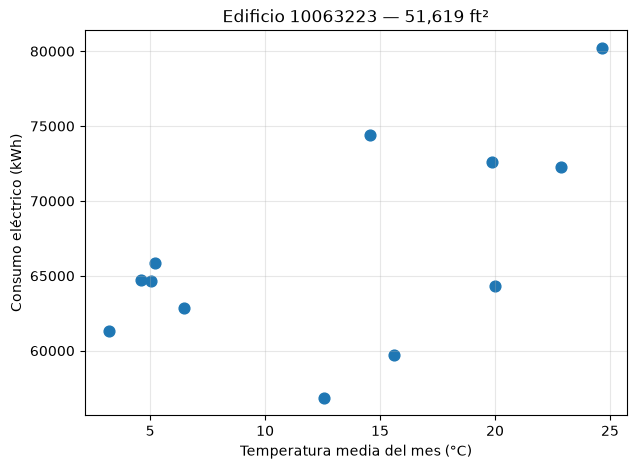

In [29]:
import matplotlib.pyplot as plt

completos = panel.groupby("property_id").filter(lambda g: len(g) == 12)
ejemplo_id = completos["property_id"].iloc[0]

ed = panel[panel["property_id"] == ejemplo_id].sort_values("mes")

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(ed["temp_c"], ed["electricity_kwh"], s=60)
ax.set_xlabel("Temperatura media del mes (°C)")
ax.set_ylabel("Consumo eléctrico (kWh)")
ax.set_title(f"Edificio {ejemplo_id} — {ed['pies2'].iloc[0]:,.0f} ft²")
ax.grid(alpha=0.3)
plt.show()

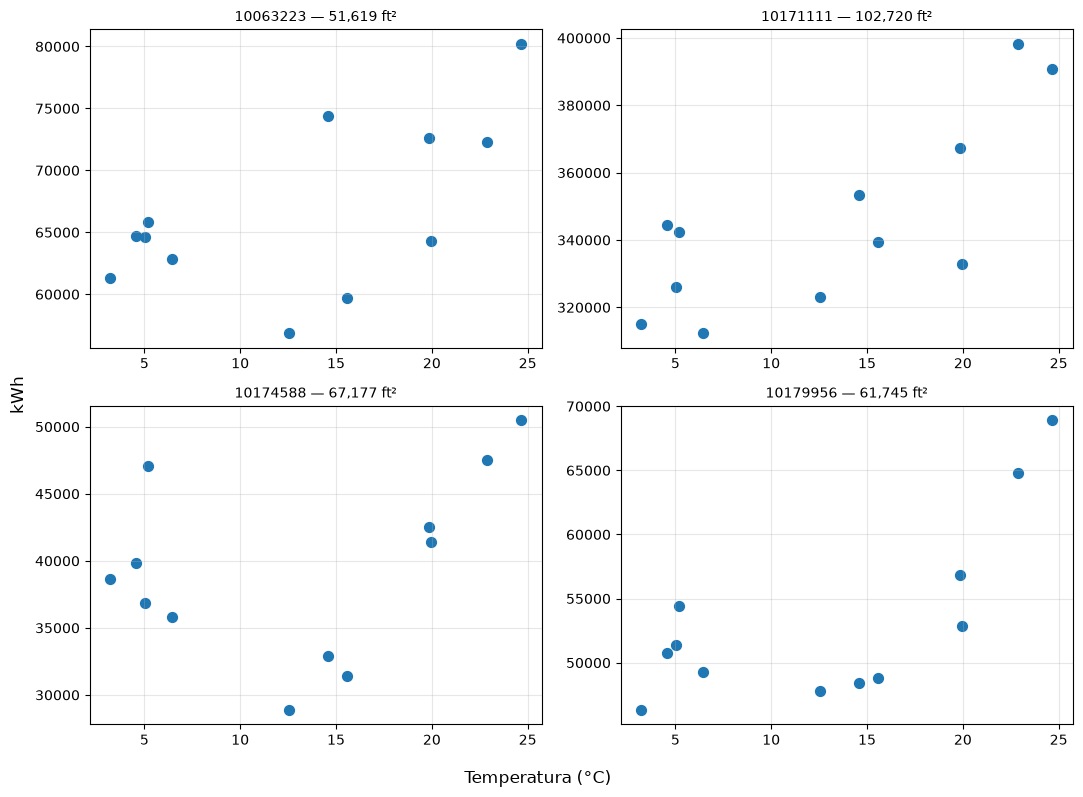

In [30]:
ids = completos["property_id"].unique()[:4]

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, pid in zip(axes.flat, ids):
    ed = panel[panel["property_id"] == pid].sort_values("mes")
    ax.scatter(ed["temp_c"], ed["electricity_kwh"], s=50)
    ax.set_title(f"{pid} — {ed['pies2'].iloc[0]:,.0f} ft²", fontsize=10)
    ax.grid(alpha=0.3)
fig.supxlabel("Temperatura (°C)")
fig.supylabel("kWh")
plt.tight_layout()
plt.show()

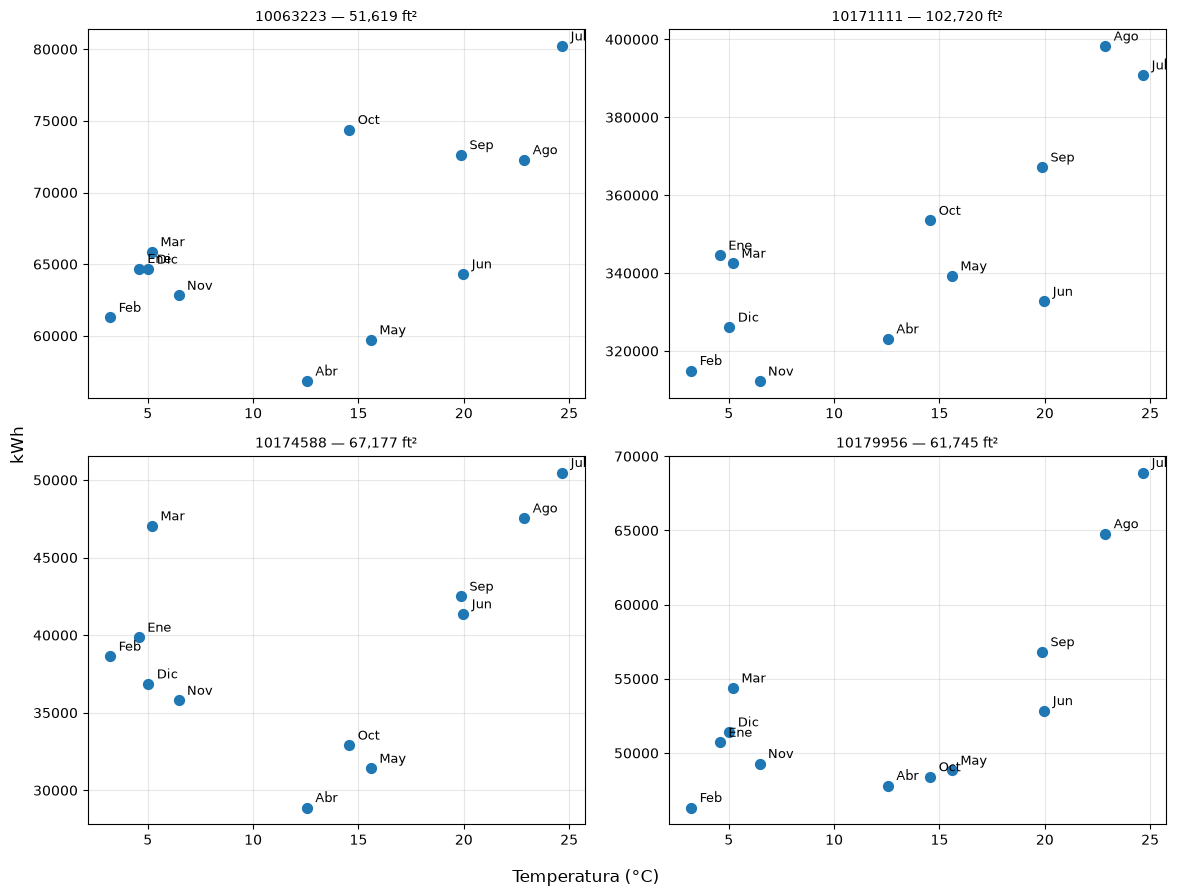

In [31]:
NOMBRES = {1:"Ene", 2:"Feb", 3:"Mar", 4:"Abr", 5:"May", 6:"Jun",
           7:"Jul", 8:"Ago", 9:"Sep", 10:"Oct", 11:"Nov", 12:"Dic"}

ids = completos["property_id"].unique()[:4]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, pid in zip(axes.flat, ids):
    ed = panel[panel["property_id"] == pid].sort_values("mes")
    ax.scatter(ed["temp_c"], ed["electricity_kwh"], s=50, zorder=3)
    for _, f in ed.iterrows():
        ax.annotate(NOMBRES[f["mes"]],
                    (f["temp_c"], f["electricity_kwh"]),
                    textcoords="offset points", xytext=(6, 4), fontsize=9)
    ax.set_title(f"{pid} — {ed['pies2'].iloc[0]:,.0f} ft²", fontsize=10)
    ax.grid(alpha=0.3)

fig.supxlabel("Temperatura (°C)")
fig.supylabel("kWh")
plt.tight_layout()
plt.show()

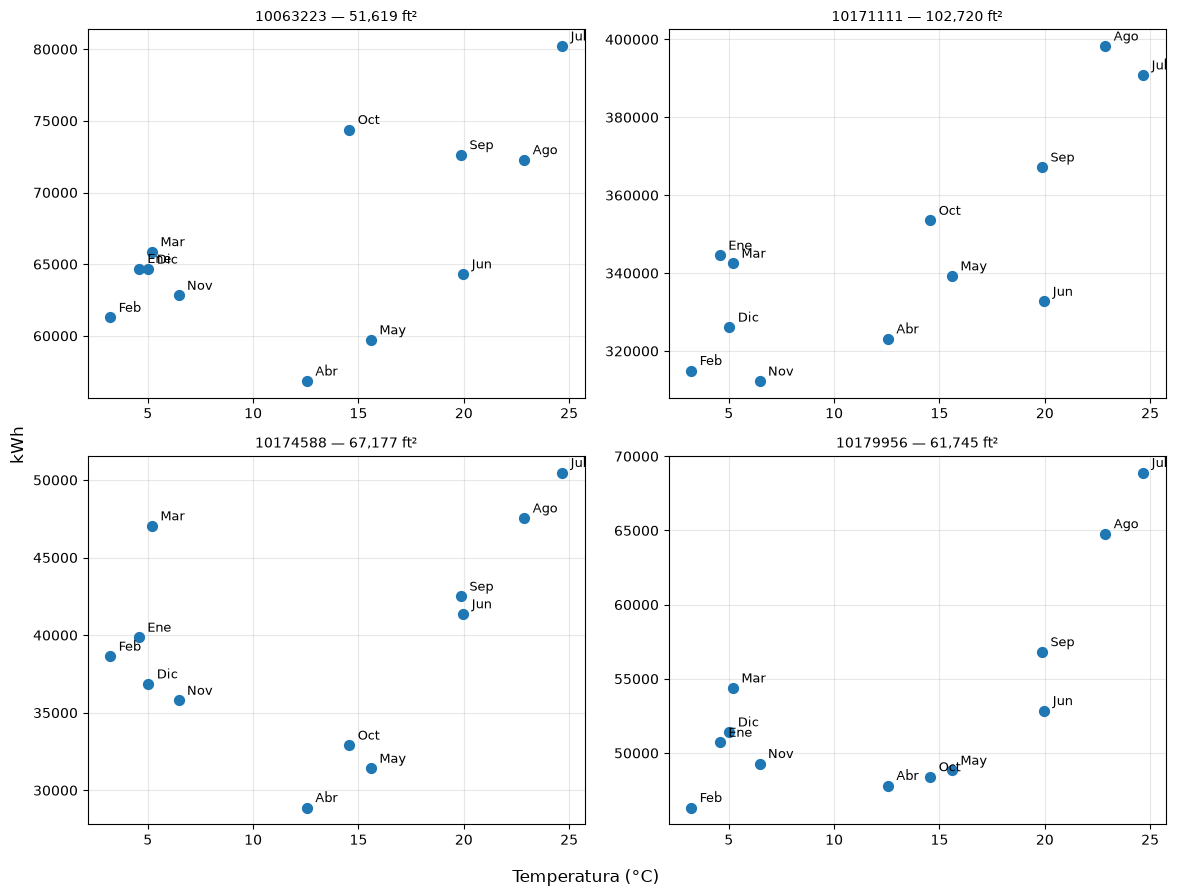

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, pid in zip(axes.flat, ids):
    ed = panel[panel["property_id"] == pid].sort_values("mes")

    ax.scatter(ed["temp_c"], ed["electricity_kwh"], s=50, zorder=3)

    for _, f in ed.iterrows():
        ax.annotate(NOMBRES[f["mes"]],
                    (f["temp_c"], f["electricity_kwh"]),
                    textcoords="offset points", xytext=(6, 4), fontsize=9)

    ax.set_title(f"{pid} — {ed['pies2'].iloc[0]:,.0f} ft²", fontsize=10)
    ax.grid(alpha=0.3)

fig.supxlabel("Temperatura (°C)")
fig.supylabel("kWh")
plt.tight_layout()
plt.savefig("grafico.png", dpi=120, bbox_inches="tight")
plt.show()

In [33]:
gas = mensual_of.copy()
gas["gas_kbtu"] = pd.to_numeric(gas["natural_gas_use_kbtu"], errors="coerce")
print(gas.groupby("mes")["gas_kbtu"].median())

mes
1     111016.0
2     106175.5
3      99175.5
4      52900.0
5      25206.0
6       7900.0
7       6596.0
8       4351.0
9       6958.0
10     31502.0
11     78853.0
12    100140.0
Name: gas_kbtu, dtype: float64


In [34]:
prom = panel.groupby("mes")["electricity_kwh"].median()
print(prom)
print()
print(f"Mediana marzo:  {prom[3]:,.0f}")
print(f"Mediana enero:  {prom[1]:,.0f}")
print(f"Mediana febrero:{prom[2]:,.0f}")

mes
1      72965.269637
2      67885.316530
3      73454.191090
4      66466.676436
5      71143.141852
6      81096.101993
7     101280.656506
8      96364.009379
9      83000.234467
10     70143.259086
11     67189.185229
12     69767.658265
Name: electricity_kwh, dtype: float64

Mediana marzo:  73,454
Mediana enero:  72,965
Mediana febrero:67,885


In [35]:
gas_por_ed = gas.groupby("property_id")["gas_kbtu"].sum()
ids_panel = set(panel["property_id"])
gas_panel = gas_por_ed[gas_por_ed.index.isin(ids_panel)]

print(f"Edificios en el panel: {len(ids_panel):,}")
print(f"Con registro de gas:   {len(gas_panel):,}")
print(f"Con gas anual = 0:     {(gas_panel == 0).sum():,}")
print(f"Sin registro de gas:   {len(ids_panel) - len(gas_panel):,}")

Edificios en el panel: 2,038
Con registro de gas:   2,038
Con gas anual = 0:     545
Sin registro de gas:   0


In [36]:
otros = mensual_of.copy()
for c in ["fuel_oil_1_use_monthly_kbtu_", "fuel_oil_2_use_monthly_kbtu_",
          "fuel_oil_4_use_monthly_kbtu_", "fuel_oil_5_6_use_monthly_kbtu_"]:
    otros[c] = pd.to_numeric(otros[c], errors="coerce").fillna(0)

otros["fuel_total"] = otros[[c for c in otros.columns if "fuel_oil" in c]].sum(axis=1)
fuel_por_ed = otros.groupby("property_id")["fuel_total"].sum()

sin_gas = gas_panel[gas_panel == 0].index
con_fuel = fuel_por_ed[fuel_por_ed.index.isin(sin_gas) & (fuel_por_ed > 0)]

print(f"Sin gas:                    {len(sin_gas):,}")
print(f"  ...pero con fuel oil:     {len(con_fuel):,}")
print(f"  ...sin gas ni fuel oil:   {len(sin_gas) - len(con_fuel):,}")

Sin gas:                    545
  ...pero con fuel oil:     97
  ...sin gas ni fuel oil:   448


In [37]:
r = requests.get(URL_ANUAL, params={
    "$limit": 50000,
    "$select": "property_id,district_steam_use_kbtu",
    "report_year": "2023",
    "primary_property_type": "Office"
})
r.raise_for_status()
vapor = pd.DataFrame(r.json())

vapor["steam"] = pd.to_numeric(vapor["district_steam_use_kbtu"], errors="coerce").fillna(0)
vapor = vapor.drop_duplicates(subset="property_id")

sin_fuel = set(sin_gas) - set(con_fuel.index)
v = vapor[vapor["property_id"].isin(sin_fuel)]

print(f"Sin gas ni fuel oil:        {len(sin_fuel):,}")
print(f"  ...con vapor > 0:         {(v['steam'] > 0).sum():,}")
print(f"  ...sin ninguna fuente:    {(v['steam'] == 0).sum():,}")
print(f"  ...no encontrados:        {len(sin_fuel) - len(v):,}")

Sin gas ni fuel oil:        448
  ...con vapor > 0:         243
  ...sin ninguna fuente:    205
  ...no encontrados:        0


In [38]:
sin_ninguna = set(v[v["steam"] == 0]["property_id"])

antes = panel["property_id"].nunique()
panel = panel[~panel["property_id"].isin(sin_ninguna)].copy()

print(f"Edificios antes:    {antes:,}")
print(f"Excluidos:          {len(sin_ninguna):,}")
print(f"Edificios después:  {panel['property_id'].nunique():,}")
print(f"Filas:              {len(panel):,}")

Edificios antes:    2,038
Excluidos:          205
Edificios después:  1,833
Filas:              21,986


Exclusión por fuente de calefacción indeterminada. El modelo 3P-C asume que el medidor eléctrico no captura calefacción. Se verificó la fuente térmica de cada edificio cruzando cuatro campos: gas natural, cuatro tipos de fuel oil, y vapor de distribución. El 90% del panel (1,833 de 2,038) tiene una fuente no eléctrica declarada. Los 205 restantes se excluyen porque no es posible descartar calefacción eléctrica, en cuyo caso los parámetros del modelo carecerían de significado físico.

**Evidencia que respalda la elección del modelo 3P-C:**

Se verificó individualmente la fuente de calefacción de cada edificio:

| Fuente | Edificios |
|---|---|
| Gas natural | 1,493 |
| Fuel oil | 97 |
| Vapor de distribución | 243 |
| Ninguna declarada (excluidos) | 205 |

El consumo mediano de gas es 26× mayor en enero (111,016 kBtu) que en agosto
(4,351 kBtu), confirmando el uso estacional para calefacción.

Para los 1,833 edificios retenidos, el medidor eléctrico captura enfriamiento
pero no calefacción, que es el supuesto del modelo 3P-C.

In [39]:
sin_ninguna = set(v[v["steam"] == 0]["property_id"])

antes = panel["property_id"].nunique()
panel = panel[~panel["property_id"].isin(sin_ninguna)].copy()

print(f"Edificios antes:    {antes:,}")
print(f"Excluidos:          {len(sin_ninguna):,}")
print(f"Edificios después:  {panel['property_id'].nunique():,}")
print(f"Filas:              {len(panel):,}")

Edificios antes:    1,833
Excluidos:          205
Edificios después:  1,833
Filas:              21,986


In [40]:
import numpy as np

def ajustar_3pc(temps, kwh, quiebre_min=8, quiebre_max=22, paso=0.25):
    temps = np.asarray(temps, dtype=float)
    kwh = np.asarray(kwh, dtype=float)

    mejor = None
    for q in np.arange(quiebre_min, quiebre_max + paso, paso):
        x = np.maximum(0.0, temps - q)
        if x.std() == 0:
            continue
        pendiente, base = np.polyfit(x, kwh, 1)
        sse = ((kwh - (base + pendiente * x)) ** 2).sum()
        if mejor is None or sse < mejor[0]:
            mejor = (sse, base, pendiente, q)

    if mejor is None:
        return None

    sse, base, pendiente, q = mejor
    sst = ((kwh - kwh.mean()) ** 2).sum()
    return base, pendiente, q, 1 - sse / sst


pid = panel["property_id"].iloc[0]
ed = panel[panel["property_id"] == pid].sort_values("mes")
base, pend, q, r2 = ajustar_3pc(ed["temp_c"], ed["electricity_kwh"])

print(f"Edificio {pid} — {ed['pies2'].iloc[0]:,.0f} ft²\n")
print(f"Base:          {base:>12,.0f} kWh/mes")
print(f"Punto quiebre: {q:>12.1f} °C")
print(f"Pendiente:     {pend:>12,.0f} kWh/°C")
print(f"R²:            {r2:>12.3f}")

Edificio 10018699 — 47,777 ft²

Base:                14,712 kWh/mes
Punto quiebre:         18.5 °C
Pendiente:              947 kWh/°C
R²:                   0.825


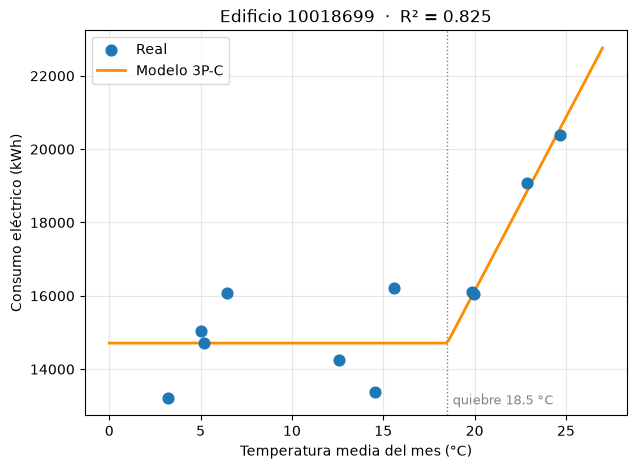

In [41]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(ed["temp_c"], ed["electricity_kwh"], s=60, zorder=3, label="Real")

tt = np.linspace(0, 27, 200)
ax.plot(tt, base + pend * np.maximum(0, tt - q),
        color="darkorange", lw=2, label="Modelo 3P-C")

ax.axvline(q, color="gray", ls=":", lw=1)
ax.annotate(f"quiebre {q:.1f} °C", (q, ax.get_ylim()[0]),
            xytext=(4, 8), textcoords="offset points", fontsize=9, color="gray")

ax.set_xlabel("Temperatura media del mes (°C)")
ax.set_ylabel("Consumo eléctrico (kWh)")
ax.set_title(f"Edificio {pid}  ·  R² = {r2:.3f}")
ax.legend()
ax.grid(alpha=0.3)
plt.savefig("ajuste_ejemplo.png", dpi=120, bbox_inches="tight")
plt.show()

In [42]:
resultados = []

for pid, g in panel.groupby("property_id"):
    if len(g) != 12:
        continue

    ajuste = ajustar_3pc(g["temp_c"], g["electricity_kwh"])
    if ajuste is None:
        continue

    base, pend, q, r2 = ajuste
    resultados.append({
        "property_id": pid,
        "base_kwh": base,
        "pendiente": pend,
        "quiebre_c": q,
        "r2": r2,
        "pies2": g["pies2"].iloc[0],
        "year_built": g["year_built"].iloc[0],
    })

params = pd.DataFrame(resultados)
params["pendiente_norm"] = params["pendiente"] / (params["pies2"] / 1000)

print(f"Edificios ajustados: {len(params):,}")
print(params[["base_kwh", "pendiente_norm", "quiebre_c", "r2"]].describe())

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_32020\1672636432.py:22: RuntimeWarning: invalid value encountered in scalar divide
  return base, pendiente, q, 1 - sse / sst


Edificios ajustados: 1,830
           base_kwh  pendiente_norm    quiebre_c           r2
count  1.830000e+03     1830.000000  1830.000000  1828.000000
mean   2.186212e+05       42.368212    14.680601     0.710355
std    4.234039e+05       47.578725     3.929206     0.278353
min    0.000000e+00     -302.107150     8.000000     0.002435
25%    3.498119e+04       22.329749    12.000000     0.549994
50%    7.350158e+04       36.912097    14.250000     0.833831
75%    2.001692e+05       56.033544    17.937500     0.927319
max    4.329891e+06      782.588231    22.000000     0.992208


In [43]:
def ajustar_3pc(temps, kwh, quiebre_min=8, quiebre_max=22, paso=0.25):
    temps = np.asarray(temps, dtype=float)
    kwh = np.asarray(kwh, dtype=float)

    sst = ((kwh - kwh.mean()) ** 2).sum()
    if sst == 0:
        return None          # consumo constante: no hay nada que modelar

    mejor = None
    for q in np.arange(quiebre_min, quiebre_max + paso, paso):
        x = np.maximum(0.0, temps - q)
        if x.std() == 0:
            continue
        pendiente, base = np.polyfit(x, kwh, 1)
        sse = ((kwh - (base + pendiente * x)) ** 2).sum()
        if mejor is None or sse < mejor[0]:
            mejor = (sse, base, pendiente, q)

    if mejor is None:
        return None

    sse, base, pendiente, q = mejor
    return base, pendiente, q, 1 - sse / sst

In [44]:
resultados = []

for pid, g in panel.groupby("property_id"):
    if len(g) != 12:
        continue

    ajuste = ajustar_3pc(g["temp_c"], g["electricity_kwh"])
    if ajuste is None:
        continue

    base, pend, q, r2 = ajuste
    resultados.append({
        "property_id": pid,
        "base_kwh": base,
        "pendiente": pend,
        "quiebre_c": q,
        "r2": r2,
        "pies2": g["pies2"].iloc[0],
        "year_built": g["year_built"].iloc[0],
    })

params = pd.DataFrame(resultados)
params["pendiente_norm"] = params["pendiente"] / (params["pies2"] / 1000)

print(f"Edificios ajustados: {len(params):,}")
print(params[["base_kwh", "pendiente_norm", "quiebre_c", "r2"]].describe())

Edificios ajustados: 1,828
           base_kwh  pendiente_norm    quiebre_c           r2
count  1.828000e+03     1828.000000  1828.000000  1828.000000
mean   2.188604e+05       42.414567    14.687910     0.710355
std    4.235738e+05       47.584093     3.925131     0.278353
min    1.695187e-01     -302.107150     8.000000     0.002435
25%    3.506802e+04       22.450764    12.000000     0.549994
50%    7.364882e+04       36.958427    14.250000     0.833831
75%    2.004067e+05       56.066173    18.000000     0.927319
max    4.329891e+06      782.588231    22.000000     0.992208


In [45]:
print(f"Pendiente negativa:      {(params['pendiente'] < 0).sum():,}")
print(f"Quiebre en el borde 8:   {(params['quiebre_c'] == 8).sum():,}")
print(f"Quiebre en el borde 22:  {(params['quiebre_c'] == 22).sum():,}")
print(f"R² < 0.7:                {(params['r2'] < 0.7).sum():,}")
print()

ok = (
    (params["r2"] >= 0.7) &
    (params["pendiente"] > 0) &
    (params["quiebre_c"] > 8) &
    (params["quiebre_c"] < 22)
)
print(f"Cumplen todos los criterios: {ok.sum():,} de {len(params):,}")

Pendiente negativa:      168
Quiebre en el borde 8:   196
Quiebre en el borde 22:  55
R² < 0.7:                635

Cumplen todos los criterios: 1,160 de 1,828


In [46]:
buenos = params[ok].copy()

print(f"Edificios finales: {len(buenos):,}\n")
print(buenos[["base_kwh", "pendiente_norm", "quiebre_c", "r2"]].describe())

Edificios finales: 1,160

           base_kwh  pendiente_norm    quiebre_c           r2
count  1.160000e+03     1160.000000  1160.000000  1160.000000
mean   2.230688e+05       49.122936    14.600216     0.888708
std    4.353455e+05       35.652578     2.833119     0.073078
min    1.914067e+03        2.301015     8.250000     0.700196
25%    3.708371e+04       29.034861    12.500000     0.846522
50%    7.311001e+04       41.745876    13.750000     0.910225
75%    1.949147e+05       59.099175    17.250000     0.946939
max    4.329891e+06      585.770204    21.750000     0.992208


In [47]:
print(buenos.nlargest(10, "pendiente_norm")[
    ["property_id", "pendiente_norm", "pies2", "quiebre_c", "r2"]])
print()
print(buenos.nsmallest(10, "quiebre_c")[
    ["property_id", "quiebre_c", "pendiente_norm", "pies2", "r2"]])

     property_id  pendiente_norm     pies2  quiebre_c        r2
1637     6696673      585.770204   26908.0      12.00  0.967883
1152     3795689      460.164101  217085.0      11.50  0.890190
1142    35424874      380.701709   25963.0      17.25  0.874066
1670     6775183      223.642066   26002.0      18.00  0.938359
602     26429216      205.124705   36351.0      17.75  0.909130
1038    33641683      192.826099   39932.0      19.50  0.760484
1712     6801393      192.223442   28320.0      14.00  0.882301
206      1582233      179.032420  373334.0      17.50  0.959658
379     21355167      177.573652   90456.0      10.50  0.961506
1403     6203957      176.745628   77698.0      14.50  0.862643

     property_id  quiebre_c  pendiente_norm      pies2        r2
1064    33972624       8.25       15.345743   183920.0  0.759450
1371     5866107       8.25       22.234726   490000.0  0.806654
1595     6671711       8.25        3.581093    48578.0  0.817776
103      1261461       8.50       2

## Bloque 5 — De pendiente a dólares

Los parámetros del modelo no son interpretables por un dueño de edificio.
Este bloque los traduce a una cifra accionable: cuánto gasta un edificio por
encima de sus pares comparables.

### 5.1 — Grupos de comparación

Comparar todos los edificios contra una única mediana sería incorrecto: los
edificios grandes tienen economías de escala, sistemas centralizados y
operación más profesionalizada. Cada edificio debe compararse contra pares de
tamaño similar.

Los cortes (50k, 100k, 250k ft²) corresponden a rangos reconocibles del
mercado de oficinas, no a percentiles de la muestra. Esto mantiene los grupos
interpretables para un lector del sector.

**Criterio de validez:** un grupo con menos de ~50 edificios no ofrece una
mediana confiable como referencia y debe fusionarse con el adyacente.

In [48]:
buenos["grupo_tamano"] = pd.cut(
    buenos["pies2"],
    bins=[0, 50_000, 100_000, 250_000, float("inf")],
    labels=["25-50k", "50-100k", "100-250k", ">250k"])

print(buenos.groupby("grupo_tamano", observed=True)["pendiente_norm"]
      .describe()[["count", "25%", "50%", "75%"]])

              count        25%        50%        75%
grupo_tamano                                        
25-50k        292.0  37.410019  52.789821  73.981443
50-100k       292.0  31.205400  44.899023  63.260099
100-250k      323.0  28.577256  39.468722  53.222417
>250k         253.0  22.592692  32.241153  43.740242


### 5.2 — Brecha contra pares

Para cada edificio se calcula la diferencia entre su pendiente normalizada y
la mediana de su grupo de tamaño. Un valor positivo indica mayor intensidad de
enfriamiento que edificios comparables.

Se usa la mediana y no la media porque la distribución tiene cola derecha larga
(máximo de 585.8 frente a una mediana de 41.7); la media estaría inflada por
casos extremos y no representaría a un edificio típico.

**Nota de interpretación:** la brecha mide desviación respecto a pares, no
ahorro alcanzable. Un edificio puede tener una carga real distinta por razones
legítimas que este análisis no observa (centro de datos, horario extendido,
densidad de ocupación).

In [49]:
medianas = (buenos.groupby("grupo_tamano", observed=True)["pendiente_norm"]
            .transform("median"))

buenos["brecha_norm"] = buenos["pendiente_norm"] - medianas
buenos["brecha_pct"] = 100 * buenos["brecha_norm"] / medianas

print(f"Por encima de su mediana: {(buenos['brecha_norm'] > 0).sum():,}")
print(f"Por debajo:               {(buenos['brecha_norm'] < 0).sum():,}")
print()
print(buenos["brecha_pct"].describe())

Por encima de su mediana: 579
Por debajo:               579

count    1160.000000
mean       15.070638
std        76.906863
min       -94.875134
25%       -28.721065
50%         0.000000
75%        38.716041
max      1065.895624
Name: brecha_pct, dtype: float64


### 5.3 — Conversión a energía anual

La pendiente expresa kWh por grado. Para obtener el exceso anual se multiplica
por los grados acumulados del año por encima del punto de quiebre específico
de cada edificio, y por su superficie.

Los grados acumulados se calculan a partir de las temperaturas medias
mensuales, ponderadas por los días de cada mes:

    grados_acumulados = Σ_meses  max(0, temp_mes − quiebre) × días_del_mes

Cada edificio tiene su propio punto de quiebre, por lo que los grados
acumulados son distintos para cada uno: un edificio que quiebra a 10 °C acumula
muchos más grados-día que uno que quiebra a 18 °C.

In [50]:
DIAS_MES = {1:31, 2:28, 3:31, 4:30, 5:31, 6:30,
            7:31, 8:31, 9:30, 10:31, 11:30, 12:31}

temps = clima_mes.set_index("mes")["temp_c"]

def grados_dia(quiebre):
    return sum(max(0, temps[m] - quiebre) * DIAS_MES[m] for m in range(1, 13))

buenos["grados_dia"] = buenos["quiebre_c"].apply(grados_dia)

buenos["kwh_exceso"] = (buenos["brecha_norm"]
                        * (buenos["pies2"] / 1000)
                        * buenos["grados_dia"] / 30)

print(buenos["grados_dia"].describe())
print()
print(f"Exceso mediano (solo los que están por encima): "
      f"{buenos.loc[buenos['kwh_exceso'] > 0, 'kwh_exceso'].median():,.0f} kWh/año")

count    1160.000000
mean      995.209612
std       462.752529
min       125.500000
25%       565.000000
50%      1074.600000
75%      1306.300000
max      2215.800000
Name: grados_dia, dtype: float64

Exceso mediano (solo los que están por encima): 42,204 kWh/año


### 5.4 — Conversión a costo

Se aplica una tarifa comercial de electricidad para traducir el exceso
energético a dólares anuales.

**Supuesto declarado:** se usa una tarifa de $0.24/kWh, representativa del
rango comercial de Con Edison en Nueva York. La tarifa real varía por
clasificación de servicio, demanda contratada y mes; este valor produce un
orden de magnitud, no una factura exacta.

El resultado debe leerse como *brecha de costo respecto a pares comparables*,
no como ahorro garantizado.

In [51]:
TARIFA_USD_KWH = 0.24

buenos["usd_exceso"] = buenos["kwh_exceso"] * TARIFA_USD_KWH

sobre = buenos[buenos["usd_exceso"] > 0]

print(f"Edificios por encima de sus pares: {len(sobre):,}\n")
print("Brecha anual en USD:")
print(f"  Mediana:       ${sobre['usd_exceso'].median():>12,.0f}")
print(f"  Percentil 75:  ${sobre['usd_exceso'].quantile(0.75):>12,.0f}")
print(f"  Percentil 90:  ${sobre['usd_exceso'].quantile(0.90):>12,.0f}")
print(f"  Máximo:        ${sobre['usd_exceso'].max():>12,.0f}")
print()
print(f"Suma total del parque: ${sobre['usd_exceso'].sum():>12,.0f}")

Edificios por encima de sus pares: 579

Brecha anual en USD:
  Mediana:       $      10,129
  Percentil 75:  $      24,702
  Percentil 90:  $      56,831
  Máximo:        $   1,110,751

Suma total del parque: $  15,885,940


In [52]:
peor = buenos.nlargest(5, "usd_exceso")
print(peor[["property_id", "pies2", "pendiente_norm", "brecha_pct",
            "quiebre_c", "grados_dia", "r2", "usd_exceso"]].to_string())

     property_id      pies2  pendiente_norm   brecha_pct  quiebre_c  grados_dia        r2    usd_exceso
1152     3795689   217085.0      460.164101  1065.895624      11.50      1520.3  0.890190  1.110751e+06
448      2364104  2291626.0       56.890325    76.452514       9.75      1894.8  0.927238  8.562477e+05
1770     7163297   796646.0       85.898230   166.424189      12.50      1306.3  0.882595  4.467096e+05
1474     6284230   685162.0       72.270102   124.154831      10.75      1680.8  0.822588  3.687852e+05
1134     3535611   408061.0       86.373829   167.899318      11.00      1627.3  0.947606  2.875691e+05


In [53]:
buenos.to_csv("datos/resultados_1160_edificios.csv", index=False)
panel.to_csv("datos/panel_final.csv", index=False)
print("Guardado")

Guardado


In [54]:
buenos = pd.read_csv("datos/resultados_1160_edificios.csv")
panel = pd.read_csv("datos/panel_final.csv")

In [55]:
import os
print(os.listdir("datos"))

['crudos', 'panel_final.csv', 'panel_oficinas_2023.csv', 'resultados_1160_edificios.csv']


## Bloque 6 — Resultados visuales

### 6.1 — Distribución de la intensidad de enfriamiento

Cada barra agrupa edificios según su pendiente normalizada (kWh por grado por
cada 1,000 ft²). La dispersión es el hallazgo central: entre edificios
comparables, el cuartil superior consume aproximadamente el doble que el
inferior.

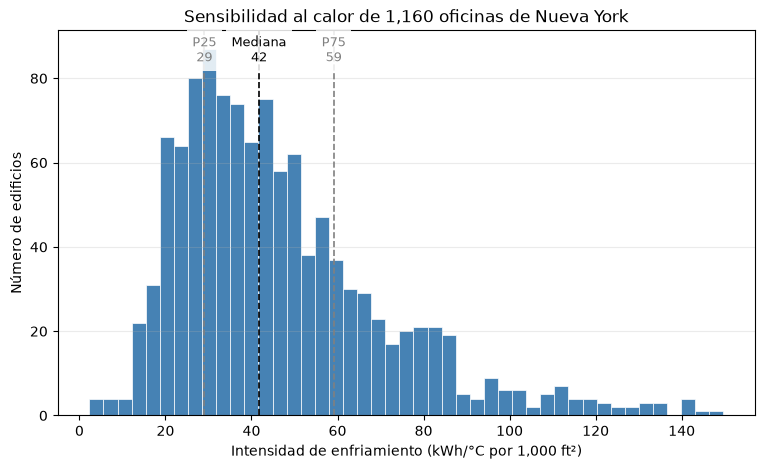

Fuera del gráfico (>150): 15 edificios


In [56]:
fig, ax = plt.subplots(figsize=(9, 5))

datos = buenos[buenos["pendiente_norm"] < 150]["pendiente_norm"]
ax.hist(datos, bins=45, color="steelblue", edgecolor="white", linewidth=0.5)

p25, p50, p75 = [buenos["pendiente_norm"].quantile(q) for q in (0.25, 0.5, 0.75)]
for v, txt, c in [(p25, f"P25\n{p25:.0f}", "gray"),
                  (p50, f"Mediana\n{p50:.0f}", "black"),
                  (p75, f"P75\n{p75:.0f}", "gray")]:
    ax.axvline(v, color=c, ls="--", lw=1.2)
    ax.annotate(txt, (v, ax.get_ylim()[1]*0.92), ha="center",
                fontsize=9, color=c,
                bbox=dict(fc="white", ec="none", alpha=0.85))

ax.set_xlabel("Intensidad de enfriamiento (kWh/°C por 1,000 ft²)")
ax.set_ylabel("Número de edificios")
ax.set_title(f"Sensibilidad al calor de {len(buenos):,} oficinas de Nueva York")
ax.grid(alpha=0.25, axis="y")

plt.savefig("fig1_distribucion.png", dpi=130, bbox_inches="tight")
plt.show()

print(f"Fuera del gráfico (>150): {(buenos['pendiente_norm'] >= 150).sum()} edificios")

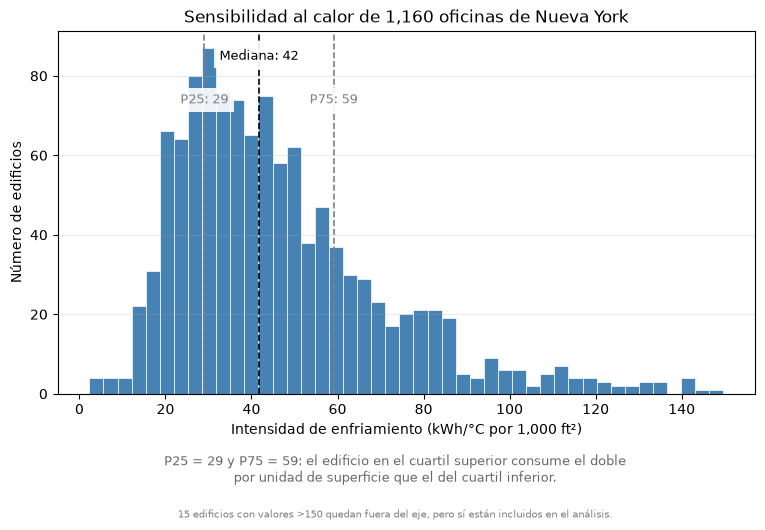

In [57]:
fig, ax = plt.subplots(figsize=(9, 5.5))

datos = buenos[buenos["pendiente_norm"] < 150]["pendiente_norm"]
fuera = (buenos["pendiente_norm"] >= 150).sum()

ax.hist(datos, bins=45, color="steelblue", edgecolor="white", linewidth=0.5)

p25, p50, p75 = [buenos["pendiente_norm"].quantile(q) for q in (0.25, 0.5, 0.75)]
ymax = ax.get_ylim()[1]

for v, txt, c, dy in [(p25, f"P25: {p25:.0f}", "gray", 0.80),
                      (p50, f"Mediana: {p50:.0f}", "black", 0.92),
                      (p75, f"P75: {p75:.0f}", "gray", 0.80)]:
    ax.axvline(v, color=c, ls="--", lw=1.2)
    ax.annotate(txt, (v, ymax*dy), ha="center", fontsize=9, color=c,
                bbox=dict(fc="white", ec="none", alpha=0.9))

ax.set_xlabel("Intensidad de enfriamiento (kWh/°C por 1,000 ft²)")
ax.set_ylabel("Número de edificios")
ax.set_title(f"Sensibilidad al calor de {len(buenos):,} oficinas de Nueva York")
ax.grid(alpha=0.25, axis="y")

fig.subplots_adjust(bottom=0.26, top=0.92)

fig.text(0.5, 0.10,
         f"P25 = {p25:.0f} y P75 = {p75:.0f}: el edificio en el cuartil superior consume el doble\n"
         f"por unidad de superficie que el del cuartil inferior.",
         ha="center", fontsize=9, color="dimgray")

fig.text(0.5, 0.035,
         f"{fuera} edificios con valores >150 quedan fuera del eje, pero sí están incluidos en el análisis.",
         ha="center", fontsize=7.5, color="gray")

plt.savefig("fig1_distribucion.png", dpi=130)
plt.show()

### 6.2 — Punto de quiebre y costo anual

El punto de quiebre es la temperatura exterior a la que el edificio comienza a
enfriar. Un valor bajo implica operar el enfriamiento durante días templados o
frescos, lo que multiplica los grados-día acumulados en el año y, con ello, el
costo.

Los cinco edificios con mayor brecha de costo tienen todos un punto de quiebre
por debajo de 12.5 °C, frente a una mediana de 13.75 °C en el parque analizado.

Este patrón es consistente con problemas de control más que de equipo:
economizadores mal calibrados, temperatura de suministro fija sin reset, o
recalentamiento simultáneo. Son fallas típicamente corregibles a bajo costo
frente a una sustitución de equipos.

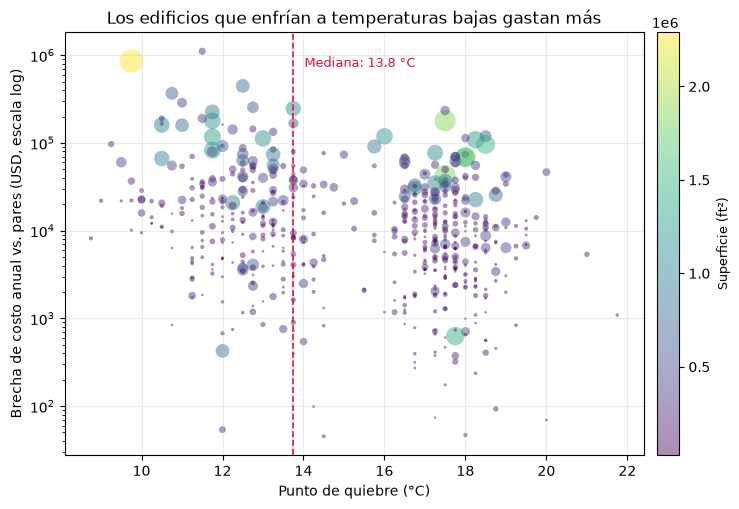

In [58]:
fig, ax = plt.subplots(figsize=(9, 5.5))

sobre = buenos[buenos["usd_exceso"] > 0]

sc = ax.scatter(sobre["quiebre_c"], sobre["usd_exceso"],
                s=sobre["pies2"] / 8000, alpha=0.45,
                c=sobre["pies2"], cmap="viridis", edgecolors="none")

ax.set_yscale("log")

med_q = buenos["quiebre_c"].median()
ax.axvline(med_q, color="crimson", ls="--", lw=1.2)
ax.annotate(f"Mediana: {med_q:.1f} °C", (med_q, ax.get_ylim()[1] * 0.4),
            xytext=(8, 0), textcoords="offset points",
            fontsize=9, color="crimson")

ax.set_xlabel("Punto de quiebre (°C)")
ax.set_ylabel("Brecha de costo anual vs. pares (USD, escala log)")
ax.set_title("Los edificios que enfrían a temperaturas bajas gastan más")
ax.grid(alpha=0.25)

cb = fig.colorbar(sc, ax=ax, pad=0.02)
cb.set_label("Superficie (ft²)", fontsize=9)

plt.savefig("fig2_quiebre_costo.png", dpi=130, bbox_inches="tight")
plt.show()

grupos = (s.groupby(pd.cut(s["quiebre_c"], [8, 12, 16, 22]), observed=True)
          ["usd_exceso"].agg(["count", "median"]))

fig, ax = plt.subplots(figsize=(8, 5))

etiquetas = ["8–12 °C\n(enfría en clima fresco)",
             "12–16 °C",
             "16–22 °C\n(operación típica)"]

barras = ax.bar(etiquetas, grupos["median"],
                color=["#c0392b", "#e67e22", "#7f8c8d"], width=0.6)

for b, (n, m) in zip(barras, grupos[["count", "median"]].values):
    ax.annotate(f"${m:,.0f}\nn={int(n)}",
                (b.get_x() + b.get_width()/2, m),
                ha="center", va="bottom", fontsize=9)

ax.set_ylabel("Brecha de costo anual vs. pares (USD, mediana)")
ax.set_title("Enfriar a temperaturas bajas cuesta 2.5× más")
ax.grid(alpha=0.25, axis="y")
ax.set_axisbelow(True)

fig.subplots_adjust(bottom=0.22)
fig.text(0.5, 0.04,
         f"Correlación de Spearman entre punto de quiebre y brecha de costo: r = {r:.2f} (n = {len(s)})",
         ha="center", fontsize=8.5, color="dimgray")

ax.set_title("Enfriar a temperaturas bajas cuesta 2.5× más", pad=20)
ax.set_ylim(0, grupos["median"].max() * 1.15)

plt.savefig("fig2_quiebre_costo.png", dpi=130)
plt.show()

In [60]:
r = requests.get(URL_ANUAL, params={
    "$limit": 5,
    "$select": "property_id,list_of_all_property_use,largest_property_use_type,data_center_gross_floor_area,office_weekly_operating_hours",
    "property_id": "3795689",
    "report_year": "2023"
})
r.raise_for_status()
print(pd.DataFrame(r.json()).to_string())

  property_id                                                                list_of_all_property_use largest_property_use_type data_center_gross_floor_area office_weekly_operating_hours
0     3795689  Worship Facility (13000.0), K-12 School (130000.0), Office (217085.0), Other (19911.0)                    Office                Not Available                            60
1     3795689  Worship Facility (13000.0), K-12 School (130000.0), Office (217085.0), Other (19911.0)                    Office                Not Available                            60


In [61]:
r = requests.get(URL_ANUAL, params={
    "$limit": 50000,
    "$select": "property_id,office_gross_floor_area_ft,property_gfa_calculated",
    "report_year": "2023",
    "primary_property_type": "Office"
})
r.raise_for_status()
areas = pd.DataFrame(r.json()).drop_duplicates(subset="property_id")

for c in ["office_gross_floor_area_ft", "property_gfa_calculated"]:
    areas[c] = pd.to_numeric(areas[c], errors="coerce")

areas["frac_oficina"] = areas["office_gross_floor_area_ft"] / areas["property_gfa_calculated"]

en_analisis = areas[areas["property_id"].isin(buenos["property_id"].astype(str))]

print(en_analisis["frac_oficina"].describe())
print()
print(f"Menos del 90% oficina: {(en_analisis['frac_oficina'] < 0.90).sum():,}")
print(f"Menos del 70% oficina: {(en_analisis['frac_oficina'] < 0.70).sum():,}")

count    1160.000000
mean        0.919031
std         0.120236
min         0.382143
25%         0.880431
50%         0.982309
75%         1.000000
max         1.000000
Name: frac_oficina, dtype: float64

Menos del 90% oficina: 324
Menos del 70% oficina: 85


In [62]:
areas["property_id"] = areas["property_id"].astype(str)
buenos["property_id"] = buenos["property_id"].astype(str)

b2 = buenos.merge(areas[["property_id", "frac_oficina"]], on="property_id", how="left")
puros = b2[b2["frac_oficina"] >= 0.90]

print(f"Edificios: {len(puros):,}\n")
print("pendiente_norm — solo edificios ≥90% oficina:")
print(puros["pendiente_norm"].describe()[["25%", "50%", "75%"]])
print()
print("Comparación con el conjunto completo:")
print(buenos["pendiente_norm"].describe()[["25%", "50%", "75%"]])

Edificios: 836

pendiente_norm — solo edificios ≥90% oficina:
25%    27.555210
50%    38.419656
75%    53.862607
Name: pendiente_norm, dtype: float64

Comparación con el conjunto completo:
25%    29.034861
50%    41.745876
75%    59.099175
Name: pendiente_norm, dtype: float64


## Corrección — Edificios de uso mixto

Al auditar el edificio con mayor brecha de costo (property_id 3795689) se
detectó que combina oficina (217,085 ft²), escuela K-12 (130,000 ft²), templo
(13,000 ft²) y otros usos (19,911 ft²).

El medidor eléctrico registra el consumo de los 379,996 ft² totales, pero la
normalización dividía únicamente entre el área de oficina. Esto sobrestima la
intensidad en todos los edificios de uso mixto.

**Alcance:** 324 de 1,160 edificios (28%) tienen menos del 90% de su
superficie destinada a oficina; 85 tienen menos del 70%.

**Decisión:** se restringe el análisis a edificios con al menos 90% de
superficie de oficina (n = 836). Se descarta normalizar por superficie total
porque implicaría comparar perfiles de uso no equivalentes.

**Efecto:** los cuartiles de intensidad bajan entre 5% y 9%; la dispersión
entre cuartiles se mantiene en ~2× (2.04 → 1.96). El hallazgo central no
depende de esta corrección.

In [63]:
buenos = puros.copy()

medianas = (buenos.groupby("grupo_tamano", observed=True)["pendiente_norm"]
            .transform("median"))
buenos["brecha_norm"] = buenos["pendiente_norm"] - medianas
buenos["brecha_pct"] = 100 * buenos["brecha_norm"] / medianas

buenos["kwh_exceso"] = (buenos["brecha_norm"]
                        * (buenos["pies2"] / 1000)
                        * buenos["grados_dia"] / 30)
buenos["usd_exceso"] = buenos["kwh_exceso"] * 0.24

sobre = buenos[buenos["usd_exceso"] > 0]

print(f"Edificios analizados: {len(buenos):,}")
print(f"Por encima de sus pares: {len(sobre):,}\n")
print(f"Brecha del cuartil superior: {buenos['brecha_pct'].quantile(0.75):.1f}%")
print(f"Brecha mediana en USD:  ${sobre['usd_exceso'].median():>10,.0f}")
print(f"Percentil 90 en USD:    ${sobre['usd_exceso'].quantile(0.90):>10,.0f}")
print(f"Total del parque:       ${sobre['usd_exceso'].sum():>10,.0f}")

Edificios analizados: 836
Por encima de sus pares: 418

Brecha del cuartil superior: 37.4%
Brecha mediana en USD:  $     9,176
Percentil 90 en USD:    $    42,454
Total del parque:       $ 8,245,618


In [64]:
s = buenos[buenos["usd_exceso"] > 0]
r = s["quiebre_c"].rank().corr(s["usd_exceso"].rank())
print(f"Spearman: {r:.3f}  (n = {len(s):,})")
print()
print(s.groupby(pd.cut(s["quiebre_c"], [8, 12, 16, 22]), observed=True)
      ["usd_exceso"].agg(["count", "median"]))

Spearman: -0.216  (n = 418)

           count        median
quiebre_c                     
(8, 12]       70  13038.953819
(12, 16]     124  10850.792148
(16, 22]     224   7365.508970


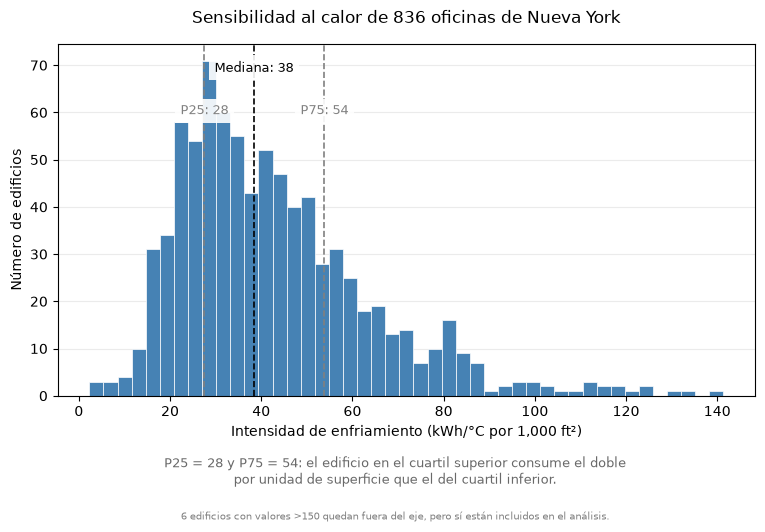

In [65]:
fig, ax = plt.subplots(figsize=(9, 5.5))

datos = buenos[buenos["pendiente_norm"] < 150]["pendiente_norm"]
fuera = (buenos["pendiente_norm"] >= 150).sum()

ax.hist(datos, bins=45, color="steelblue", edgecolor="white", linewidth=0.5)

p25, p50, p75 = [buenos["pendiente_norm"].quantile(q) for q in (0.25, 0.5, 0.75)]
ymax = ax.get_ylim()[1]

for v, txt, c, dy in [(p25, f"P25: {p25:.0f}", "gray", 0.80),
                      (p50, f"Mediana: {p50:.0f}", "black", 0.92),
                      (p75, f"P75: {p75:.0f}", "gray", 0.80)]:
    ax.axvline(v, color=c, ls="--", lw=1.2)
    ax.annotate(txt, (v, ymax*dy), ha="center", fontsize=9, color=c,
                bbox=dict(fc="white", ec="none", alpha=0.9))

ax.set_xlabel("Intensidad de enfriamiento (kWh/°C por 1,000 ft²)")
ax.set_ylabel("Número de edificios")
ax.set_title(f"Sensibilidad al calor de {len(buenos):,} oficinas de Nueva York", pad=15)
ax.grid(alpha=0.25, axis="y")
ax.set_axisbelow(True)

fig.subplots_adjust(bottom=0.26, top=0.90)

fig.text(0.5, 0.10,
         f"P25 = {p25:.0f} y P75 = {p75:.0f}: el edificio en el cuartil superior consume el doble\n"
         f"por unidad de superficie que el del cuartil inferior.",
         ha="center", fontsize=9, color="dimgray")

fig.text(0.5, 0.035,
         f"{fuera} edificios con valores >150 quedan fuera del eje, pero sí están incluidos en el análisis.",
         ha="center", fontsize=7.5, color="gray")

plt.savefig("fig1_distribucion.png", dpi=130)
plt.show()

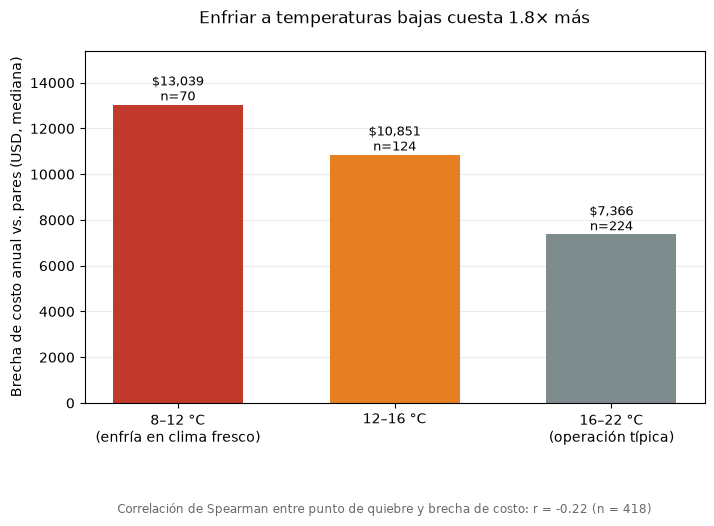

           count        median
quiebre_c                     
(8, 12]       70  13038.953819
(12, 16]     124  10850.792148
(16, 22]     224   7365.508970

Razón: 1.77×   Spearman: -0.216


In [66]:
s = buenos[buenos["usd_exceso"] > 0]
r = s["quiebre_c"].rank().corr(s["usd_exceso"].rank())

grupos = (s.groupby(pd.cut(s["quiebre_c"], [8, 12, 16, 22]), observed=True)
          ["usd_exceso"].agg(["count", "median"]))

razon = grupos["median"].iloc[0] / grupos["median"].iloc[-1]

fig, ax = plt.subplots(figsize=(8, 5.5))

etiquetas = ["8–12 °C\n(enfría en clima fresco)",
             "12–16 °C",
             "16–22 °C\n(operación típica)"]

barras = ax.bar(etiquetas, grupos["median"],
                color=["#c0392b", "#e67e22", "#7f8c8d"], width=0.6)

for b, (n, m) in zip(barras, grupos[["count", "median"]].values):
    ax.annotate(f"${m:,.0f}\nn={int(n)}",
                (b.get_x() + b.get_width()/2, m),
                ha="center", va="bottom", fontsize=9)

ax.set_ylim(0, grupos["median"].max() * 1.18)
ax.set_ylabel("Brecha de costo anual vs. pares (USD, mediana)")
ax.set_title(f"Enfriar a temperaturas bajas cuesta {razon:.1f}× más", pad=20)
ax.grid(alpha=0.25, axis="y")
ax.set_axisbelow(True)

fig.subplots_adjust(bottom=0.24)
fig.text(0.5, 0.04,
         f"Correlación de Spearman entre punto de quiebre y brecha de costo: "
         f"r = {r:.2f} (n = {len(s):,})",
         ha="center", fontsize=8.5, color="dimgray")

plt.savefig("fig2_quiebre_costo.png", dpi=130)
plt.show()

print(grupos)
print(f"\nRazón: {razon:.2f}×   Spearman: {r:.3f}")

In [67]:
   print(len(buenos))
   buenos.to_csv("datos/resultados_836_edificios.csv", index=False)

836
